# Лабораторна робота №5
**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv
Використано оригінальний CSV з Kaggle, версія 1. Фактичний період даних перевіряється у виводі, а не визначається лише з назви файлу.

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.

Для Colab за потреби встановіть залежності в окремій клітинці: `%pip install prophet statsmodels tensorflow`. Для однакового порівняння всі моделі прогнозують весь test з однієї точки; LSTM не отримує фактичних температур test як наступних входів.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [1]:
from pathlib import Path
import io,zipfile,urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from statsmodels.graphics.tsaplots import plot_acf,plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error,mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from prophet import Prophet
import tensorflow as tf
from tensorflow import keras
tf.keras.utils.set_random_seed(42)

In [2]:
file=Path('kaggel_weather_2013_to_2024.csv')
if not file.exists():file=Path('Джерельні файли')/file
if not file.exists():
    url='https://www.kaggle.com/api/v1/datasets/download/yug201/daily-climate-time-series-data-delhi-india?datasetVersionNumber=1'
    archive=urllib.request.urlopen(url,timeout=90).read()
    with zipfile.ZipFile(io.BytesIO(archive)) as z:
        csv=next(n for n in z.namelist() if n.endswith('.csv'))
        file=Path(csv).name
        Path(file).write_bytes(z.read(csv))
print('Файл:',file)

Файл: kaggel_weather_2013_to_2024.csv


In [3]:
df=pd.read_csv(file)
display(df.head())
df.info()
display(df.describe())

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non-null   object 
 15  Year

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
mean,1778.000000,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


Підготовка даних

In [4]:
df['DATE']=pd.to_datetime(df['DATE'],format='%m/%d/%Y')
print('Дублі дат:',df['DATE'].duplicated().sum())
df=df.sort_values('DATE').drop_duplicates('DATE').set_index('DATE')
df=df.drop(columns=[c for c in df if c.startswith('Unnamed:')])
original_dates=df.index.copy()
df=df.asfreq('D')
print('Відсутні календарні дні:',len(df)-len(original_dates))
print('Період:',df.index.min().date(),df.index.max().date())

Дублі дат: 1
Відсутні календарні дні: 693
Період: 2013-04-14 2024-11-30


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 4249 entries, 2013-04-14 to 2024-11-30
Freq: D
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   tempmax                3556 non-null   float64
 1   tempmin                3556 non-null   float64
 2   temp                   3556 non-null   float64
 3   feelslikemax           3556 non-null   float64
 4   feelslikemin           3556 non-null   float64
 5   feelslike              3556 non-null   float64
 6   humidity               3556 non-null   float64
 7   precip                 3556 non-null   float64
 8   precipprob             3556 non-null   float64
 9   precipcover            3556 non-null   float64
 10  windspeed              3556 non-null   float64
 11  sealevelpressure       3556 non-null   float64
 12  conditions             3556 non-null   object 
 13  Year                   3556 non-null   float64
 14  month                  3556 no

In [6]:
display(df.isna().sum())
observed_temperature=df['temp'].notna()
df['temp']=df['temp'].ffill()
if df['temp'].isna().any():raise ValueError('На початку ряду є пропуски температури')
print('Пропуски temp після причинного ffill:',df['temp'].isna().sum())

,0
tempmax,693
tempmin,693
temp,693
feelslikemax,693
feelslikemin,693
feelslike,693
humidity,693
precip,693
precipprob,693
precipcover,693


Пропуски temp після причинного ffill: 0


Графік температури

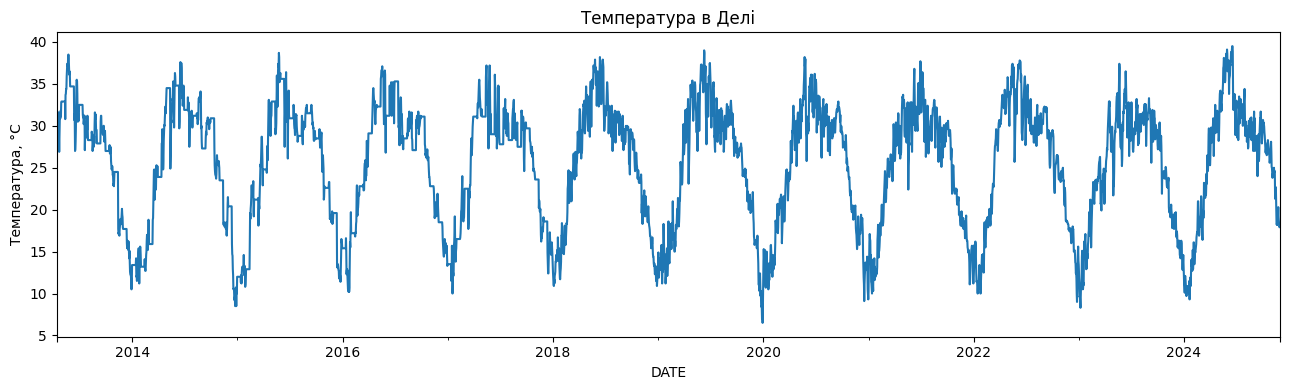

In [7]:
df['temp'].plot(figsize=(13,4),title='Температура в Делі')
plt.ylabel('Температура, °C')
plt.tight_layout()
plt.show()

Ковзне середнє

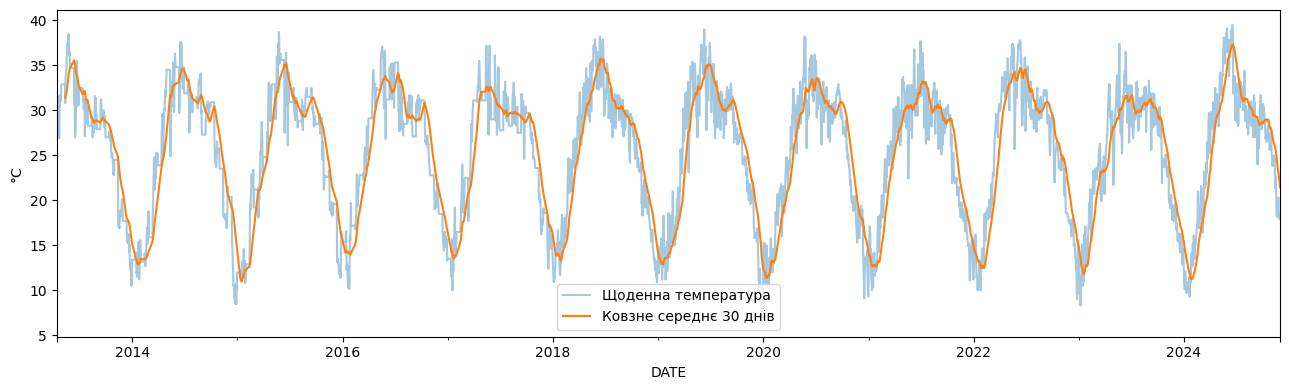

In [8]:
ax=df['temp'].plot(figsize=(13,4),alpha=0.4,label='Щоденна температура')
df['temp'].rolling(30).mean().plot(ax=ax,label='Ковзне середнє 30 днів')
plt.legend()
plt.ylabel('°C')
plt.tight_layout()
plt.show()

Розподіл температури

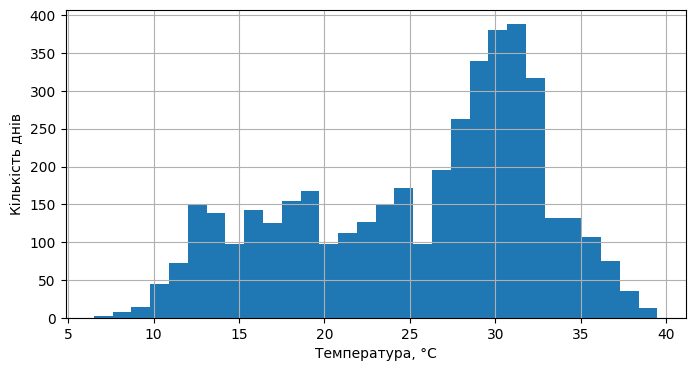

In [9]:
df['temp'].hist(bins=30,figsize=(8,4))
plt.xlabel('Температура, °C')
plt.ylabel('Кількість днів')
plt.show()

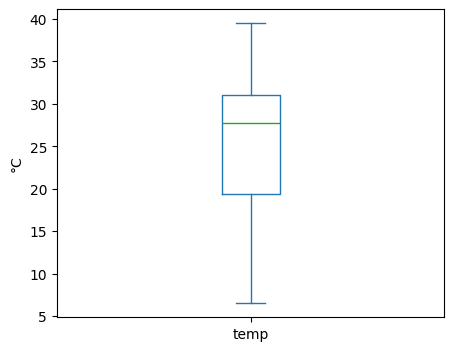

In [10]:
df[['temp']].plot.box(figsize=(5,4))
plt.ylabel('°C')
plt.show()

Аналіз автокореляції
ACF

PACF

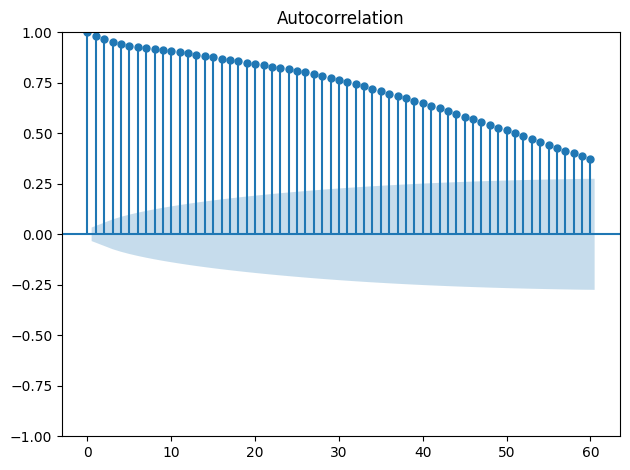

In [11]:
split=int(len(df)*0.8)
plot_acf(df['temp'].iloc[:split],lags=60)
plt.tight_layout()
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній : значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

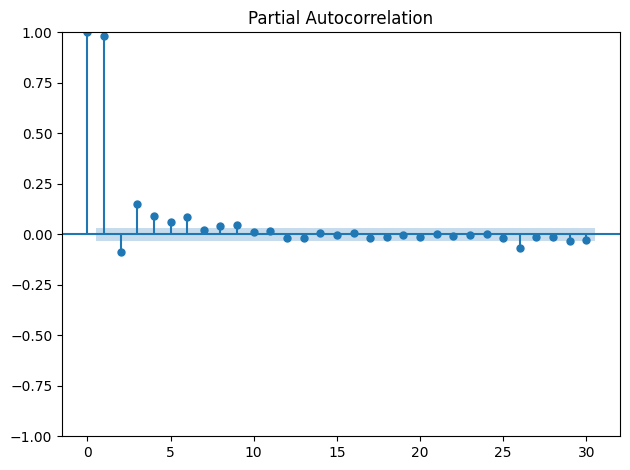

In [12]:
plot_pacf(df['temp'].iloc[:split],lags=30,method='ywm')
plt.tight_layout()
plt.show()

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [13]:
series=df['temp']
train=series.iloc[:split]
test=series.iloc[split:]
evaluation_mask=observed_temperature.loc[test.index].to_numpy()
print('Train:',train.index.min(),train.index.max(),len(train))
print('Test:',test.index.min(),test.index.max(),len(test))
print('Оцінювані фактично виміряні дні test:',evaluation_mask.sum())

Train: 2013-04-14 00:00:00 2022-08-03 00:00:00 3399
Test: 2022-08-04 00:00:00 2024-11-30 00:00:00 850
Оцінювані фактично виміряні дні test: 848


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [14]:
arima=ARIMA(train,order=(5,1,0)).fit()
arima_pred=pd.Series(arima.forecast(len(test)).to_numpy(),index=test.index)

In [15]:
print(arima.summary())

                               SARIMAX Results                                
Dep. Variable:                   temp   No. Observations:                 3399
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -5606.986
Date:                Tue, 17 Nov 2026   AIC                          11225.972
Time:                        19:57:05   BIC                          11262.757
Sample:                    04-14-2013   HQIC                         11239.120
                         - 08-03-2022                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0616      0.014      4.479      0.000       0.035       0.089
ar.L2         -0.1716      0.015    -11.742      0.000      -0.200      -0.143
ar.L3         -0.1061      0.015     -6.979      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

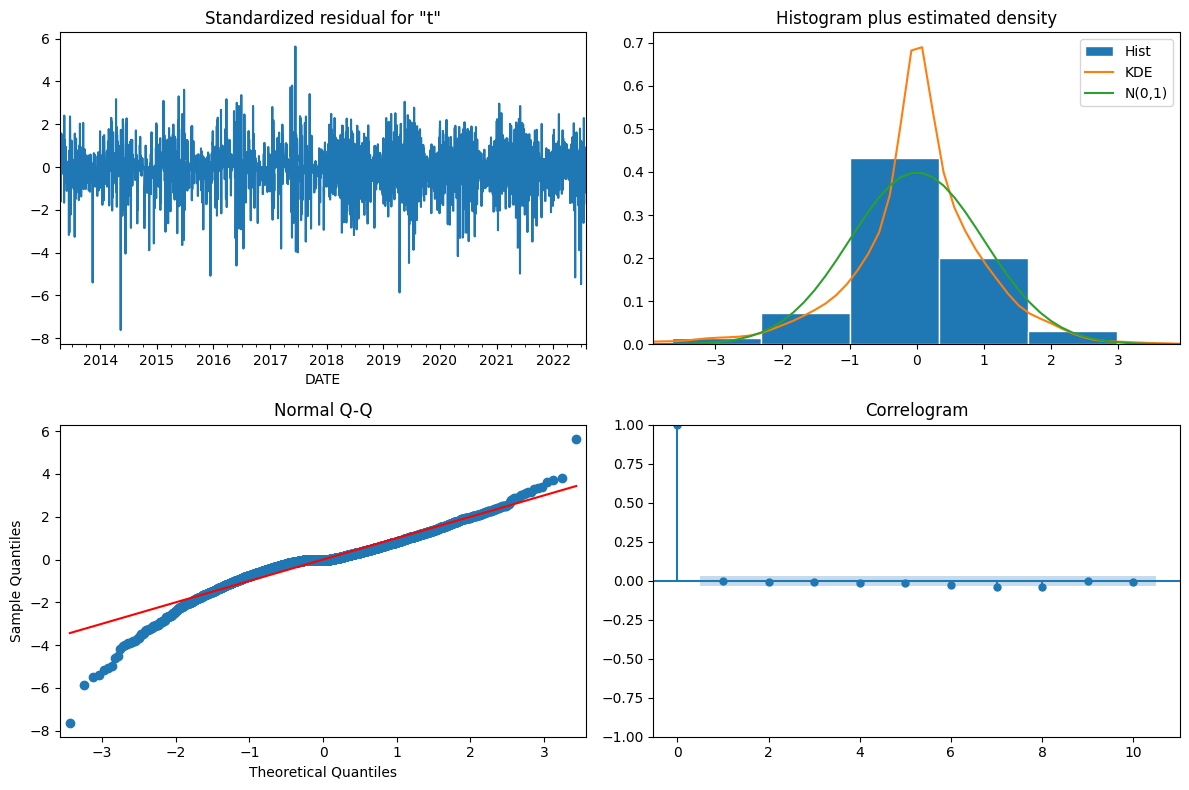

In [16]:
arima.plot_diagnostics(figsize=(12,8))
plt.tight_layout()
plt.show()

In [17]:
def metrics(actual,pred):
    actual=np.asarray(actual)[evaluation_mask]
    pred=np.asarray(pred)[evaluation_mask]
    nonzero=np.abs(actual)>1e-8
    return {'MAE':mean_absolute_error(actual,pred),'RMSE':np.sqrt(mean_squared_error(actual,pred)),'MAPE, %':100*np.mean(np.abs((actual[nonzero]-pred[nonzero])/actual[nonzero]))}
arima_metrics=metrics(test,arima_pred)
display(pd.Series(arima_metrics))

,0
MAE,6.249233
RMSE,8.469006
"MAPE, %",36.121038


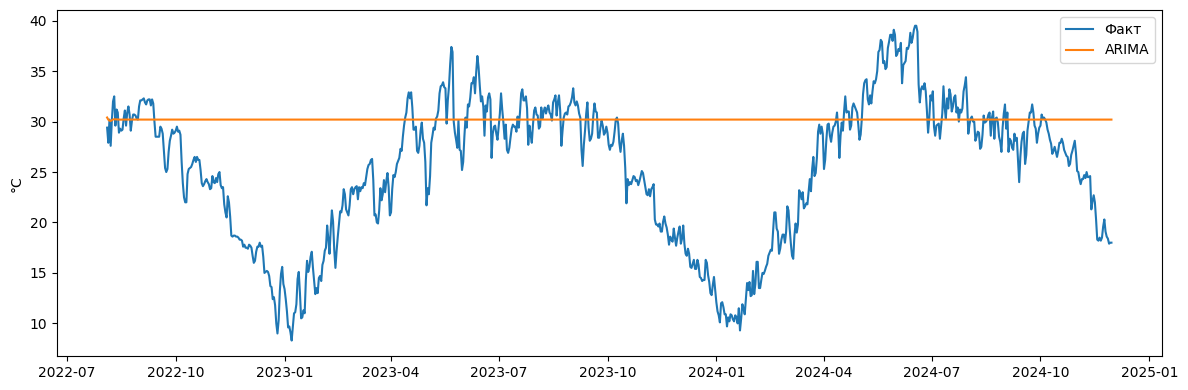

In [18]:
plt.figure(figsize=(12,4))
plt.plot(test.index,test,label='Факт')
plt.plot(test.index,arima_pred,label='ARIMA')
plt.legend()
plt.ylabel('°C')
plt.tight_layout()
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [19]:
prophet_train=train.rename('y').rename_axis('ds').reset_index()
display(prophet_train.head())

,ds,y
0,2013-04-14,28.7
1,2013-04-15,28.6
2,2013-04-16,31.7
3,2013-04-17,29.9
4,2013-04-18,30.6


In [20]:
prophet=Prophet(yearly_seasonality=True,weekly_seasonality=False,daily_seasonality=False)
prophet.fit(prophet_train)

Прогноз

In [21]:
future=pd.DataFrame({'ds':test.index})
forecast=prophet.predict(future)
prophet_pred=pd.Series(forecast['yhat'].to_numpy(),index=test.index)

In [22]:
prophet_metrics=metrics(test,prophet_pred)
display(pd.Series(prophet_metrics))

,0
MAE,2.054720
RMSE,2.624395
"MAPE, %",9.305382


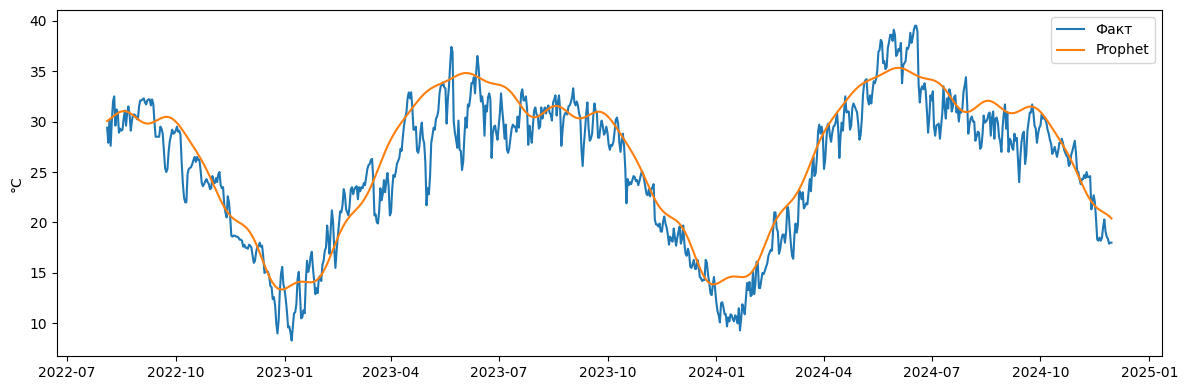

In [23]:
plt.figure(figsize=(12,4))
plt.plot(test.index,test,label='Факт')
plt.plot(test.index,prophet_pred,label='Prophet')
plt.legend()
plt.ylabel('°C')
plt.tight_layout()
plt.show()

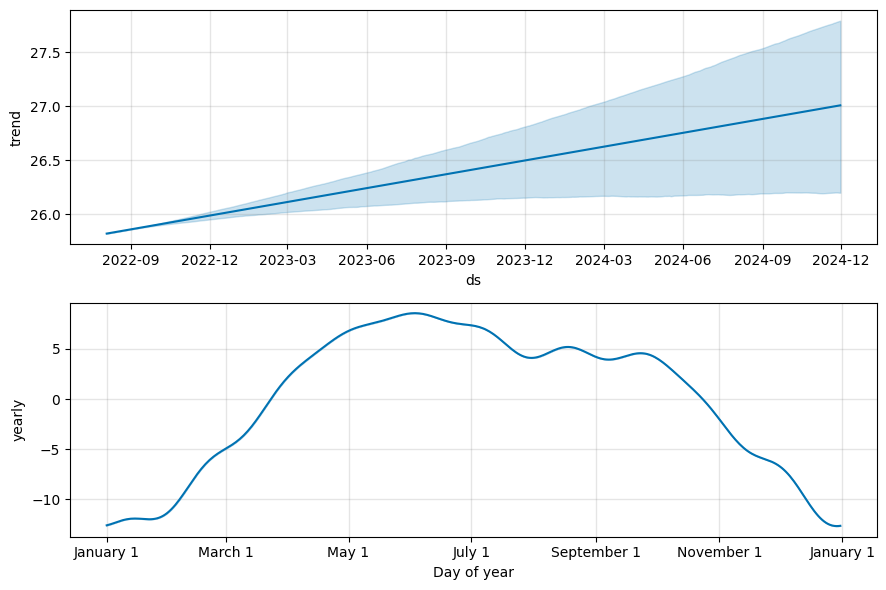

In [24]:
prophet.plot_components(forecast)
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [25]:
lookback=30
validation_start=int(len(train)*0.85)
scaler=MinMaxScaler().fit(train.iloc[:validation_start].to_numpy().reshape(-1,1))
train_scaled=scaler.transform(train.to_numpy().reshape(-1,1)).ravel()
X_seq=np.array([train_scaled[i-lookback:i] for i in range(lookback,len(train))])[...,None]
y_seq=train_scaled[lookback:]
print('Послідовності train:',X_seq.shape)

Послідовності train: (3369, 30, 1)


In [26]:
boundary=validation_start-lookback
X_fit,X_val=X_seq[:boundary],X_seq[boundary:]
y_fit,y_val=y_seq[:boundary],y_seq[boundary:]
print('Навчання:',X_fit.shape,'Validation:',X_val.shape,'Test залишається майбутнім горизонтом:',len(test))

Навчання: (2859, 30, 1) Validation: (510, 30, 1) Test залишається майбутнім горизонтом: 850


In [27]:
lstm=keras.Sequential([keras.layers.Input((lookback,1)),keras.layers.LSTM(32),keras.layers.Dense(16,activation='relu'),keras.layers.Dense(1)])
lstm.compile(optimizer=keras.optimizers.Adam(0.001),loss='mse')

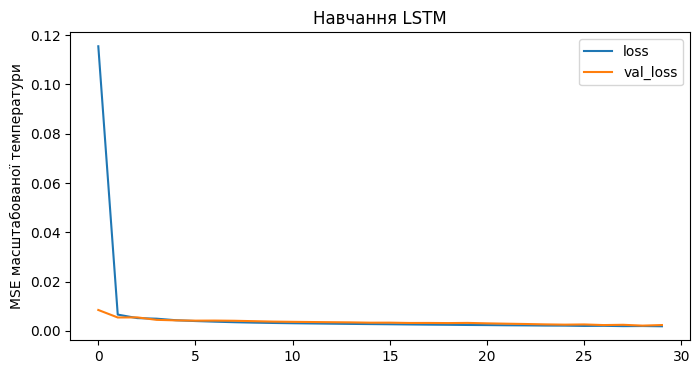

In [28]:
history=lstm.fit(X_fit,y_fit,validation_data=(X_val,y_val),epochs=30,batch_size=32,shuffle=False,verbose=0,callbacks=[keras.callbacks.EarlyStopping(patience=5,restore_best_weights=True)])
pd.DataFrame(history.history).plot(figsize=(8,4),title='Навчання LSTM')
plt.ylabel('MSE масштабованої температури')
plt.show()

In [29]:
lstm.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,693 (57.40 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 9,796 (38.27 KB)

In [30]:
window=train_scaled[-lookback:].copy()
scaled_predictions=[]
for step in range(len(test)):
    prediction=float(lstm(window.reshape(1,lookback,1),training=False).numpy()[0,0])
    scaled_predictions.append(prediction)
    window=np.append(window[1:],prediction)
lstm_values=scaler.inverse_transform(np.array(scaled_predictions).reshape(-1,1)).ravel()

In [31]:
lstm_pred=pd.Series(lstm_values,index=test.index)
print('Мітки прогнозу:',lstm_pred.index.min(),lstm_pred.index.max())

Мітки прогнозу: 2022-08-04 00:00:00 2024-11-30 00:00:00


In [32]:
lstm_metrics=metrics(test,lstm_pred)
display(pd.Series(lstm_metrics))

,0
MAE,9.841660
RMSE,11.510224
"MAPE, %",35.869876


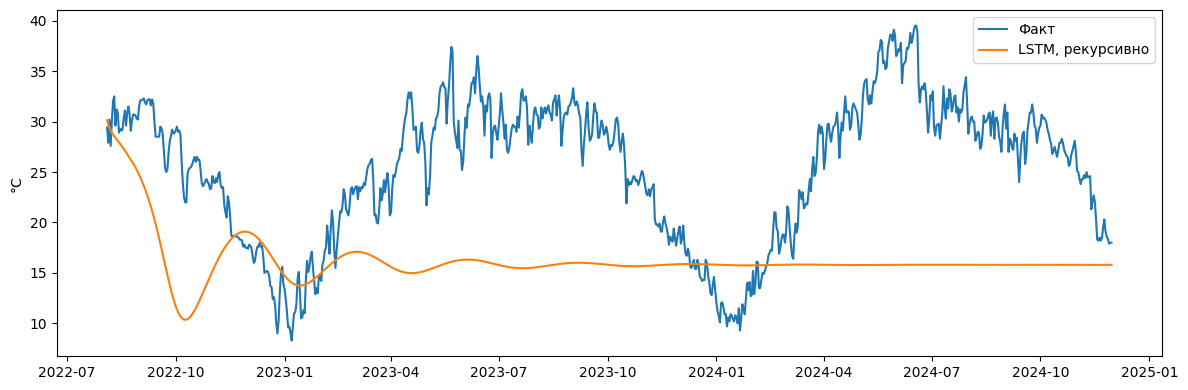

In [33]:
plt.figure(figsize=(12,4))
plt.plot(test.index,test,label='Факт')
plt.plot(test.index,lstm_pred,label='LSTM, рекурсивно')
plt.legend()
plt.ylabel('°C')
plt.tight_layout()
plt.show()

Порівняння моделей

,MAE,RMSE,"MAPE, %"
Prophet,2.054720,2.624395,9.305382
ARIMA,6.249233,8.469006,36.121038
LSTM,9.841660,11.510224,35.869876


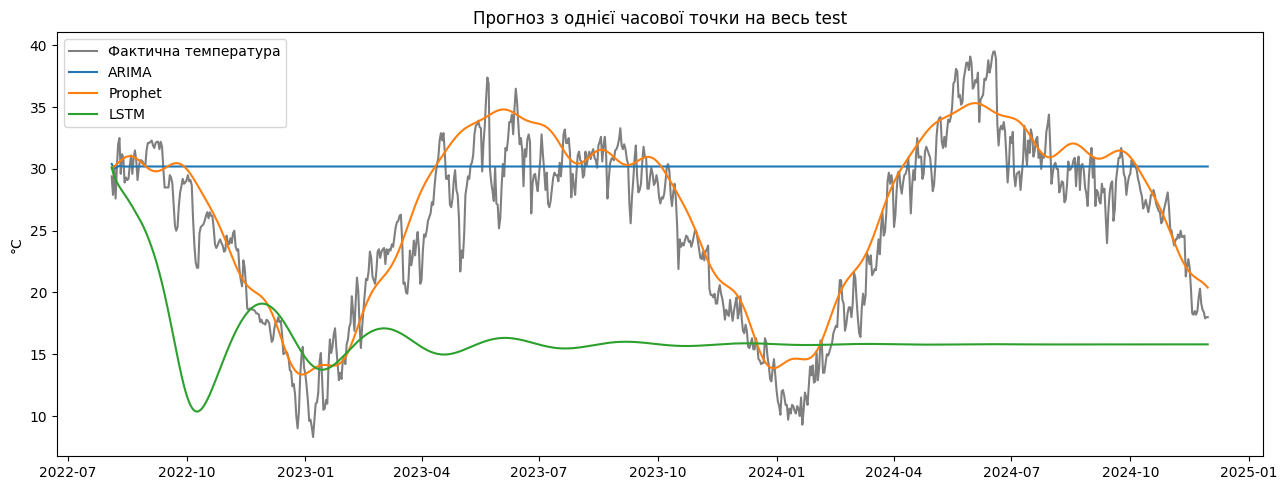

In [34]:
results=pd.DataFrame({'ARIMA':arima_metrics,'Prophet':prophet_metrics,'LSTM':lstm_metrics}).T.sort_values('RMSE')
display(results)
plt.figure(figsize=(13,5))
plt.plot(test.index,test,label='Фактична температура',color='black',alpha=0.5)
for name,pred in [('ARIMA',arima_pred),('Prophet',prophet_pred),('LSTM',lstm_pred)]:plt.plot(test.index,pred,label=name)
plt.ylabel('°C')
plt.title('Прогноз з однієї часової точки на весь test')
plt.legend()
plt.tight_layout()
plt.show()

## Висновок

Проаналізовано щоденну температуру в Делі за 2013-04-14 - 2024-11-30. На графіку видно виражену річну сезонність, а ACF і PACF на train показують залежність сусідніх спостережень. Дані поділено у часовому порядку: 3399 днів train та 850 днів test; пропуски заповнено лише попереднім значенням, оцінювання проводилося за виміряними test-днями. ARIMA(5,1,0), Prophet та LSTM прогнозували весь тестовий горизонт з однієї початкової точки без використання фактичних значень усередині test. Найменший RMSE отримала **Prophet**: 2.624 °C, MAE=2.055 °C, MAPE=9.31%. Результати трьох моделей наведено в порівняльній таблиці. Проста ARIMA не має річної сезонної складової, а рекурсивна LSTM накопичує похибку на довгому горизонті. MAPE для температури за Цельсієм залежить від шкали й може бути нестійкою біля нуля, тому основним критерієм порівняння обрано RMSE. Для кращої оцінки потрібні rolling backtesting і підбір параметрів лише всередині train.